### Langchain version v1

In [18]:
import langchain
langchain.__version__

'1.4.9'

In [14]:
import os
from dotenv import load_dotenv
load_dotenv()

# os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"] = os.getenv("GROQ_API_KEY")
groq_api_key = os.getenv("GROQ_API_KEY")

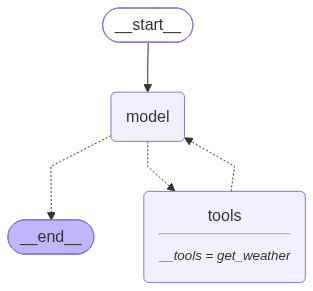

In [16]:
from langchain.agents import create_agent
from langchain_groq import ChatGroq

def get_weather(city: str) -> str:
    """Get the weather for a city"""
    return f"The weater in {city} is sunny."

model = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=groq_api_key
)

agent = create_agent(
    model=model,
    tools=[get_weather],
    system_prompt="You are a helpful assistant."
)

agent

In [17]:
agent.invoke({"messages": [{"role": "user", "content": "What is the weather in New York?"}]})

{'messages': [HumanMessage(content='What is the weather in New York?', additional_kwargs={}, response_metadata={}, id='ff436ce1-c22a-4283-9a76-6cd3a8c2f534'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'The user asks for weather in New York. We have a function get_weather. We should call it with city "New York".', 'tool_calls': [{'id': 'fc_2b577450-5008-4e27-b58c-9c66cc38a9f9', 'function': {'arguments': '{"city":"New York"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 137, 'total_tokens': 192, 'completion_time': 0.115178113, 'completion_tokens_details': {'reasoning_tokens': 27}, 'prompt_time': 0.025028552, 'prompt_tokens_details': None, 'queue_time': 0.164530827, 'total_time': 0.140206665}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1c